# Random Forest for Detection Fraud from Banking Transaction

## Import Library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

## Load Dataset

In [46]:
file_path = Path('../dataset/Fraud Detection Dataset.csv')

if file_path.exists() :
    df = pd.read_csv(file_path)
    print("Load Dataset Succesfully")
else :
    print(f"Error : {file_path} does't exists")

Load Dataset Succesfully


## Data Understanding

In [47]:
df.shape

(51000, 12)

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_ID                    51000 non-null  str    
 1   User_ID                           51000 non-null  int64  
 2   Transaction_Amount                48480 non-null  float64
 3   Transaction_Type                  51000 non-null  str    
 4   Time_of_Transaction               48448 non-null  float64
 5   Device_Used                       48527 non-null  str    
 6   Location                          48453 non-null  str    
 7   Previous_Fraudulent_Transactions  51000 non-null  int64  
 8   Account_Age                       51000 non-null  int64  
 9   Number_of_Transactions_Last_24H   51000 non-null  int64  
 10  Payment_Method                    48531 non-null  str    
 11  Fraudulent                        51000 non-null  int64  
dtypes: float64(2), 

In [49]:
df.describe()

,User_ID,Transaction_Amount,Time_of_Transaction,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Fraudulent
count,51000.000000,48480.000000,48448.000000,51000.000000,51000.000000,51000.000000,51000.000000
mean,3005.110176,2996.249784,11.488400,1.995725,60.033902,7.495588,0.049216
std,1153.121107,5043.932555,6.922954,1.415150,34.384131,4.020080,0.216320
min,1000.000000,5.030000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,2007.000000,1270.552500,5.000000,1.000000,30.000000,4.000000,0.000000
50%,2996.000000,2524.100000,12.000000,2.000000,60.000000,7.000000,0.000000
75%,4006.000000,3787.240000,17.000000,3.000000,90.000000,11.000000,0.000000
max,4999.000000,49997.800000,23.000000,4.000000,119.000000,14.000000,1.000000


In [50]:
df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [51]:
df.tail()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
50995,T33982,2339,3112.51,Bill Payment,15.0,Mobile,New York,0,7,8,Debit Card,0
50996,T31261,2152,2897.15,Online Purchase,3.0,Mobile,Miami,1,75,11,Net Banking,1
50997,T12293,3345,2204.43,POS Payment,18.0,Mobile,San Francisco,3,73,5,Credit Card,0
50998,T42287,1518,4787.17,POS Payment,19.0,Tablet,New York,2,108,14,Net Banking,0
50999,T13665,2315,814.72,POS Payment,3.0,Tablet,Los Angeles,0,50,10,Invalid Method,0


## Exploratory Data Analysis (EDA)

In [52]:
print(df.isna().sum().sort_values(ascending=False).to_string())

Time_of_Transaction                 2552
Location                            2547
Transaction_Amount                  2520
Device_Used                         2473
Payment_Method                      2469
Transaction_Type                       0
Transaction_ID                         0
User_ID                                0
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Fraudulent                             0


In [53]:
df.duplicated().sum()

np.int64(881)

Fraudulent
0    95.078431
1     4.921569
Name: proportion, dtype: float64


C:\Users\ROG\AppData\Local\Temp\ipykernel_22412\970916489.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


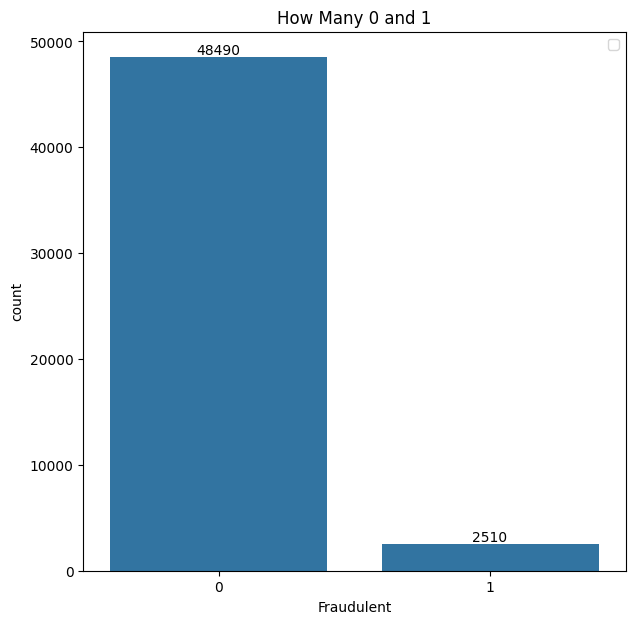

In [54]:
percent_fraud = df['Fraudulent'].value_counts(normalize=True) * 100
print(percent_fraud)

plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Fraudulent'], hue_order=['0', '1'])
ax.bar_label(ax.containers[0])
plt.title('How Many 0 and 1')
plt.legend()
plt.show()


# Imbalance Data 

Transaction_Type
Bill Payment       10340
Bank Transfer      10276
ATM Withdrawal     10164
POS Payment        10126
Online Purchase    10094
Name: count, dtype: int64


C:\Users\ROG\AppData\Local\Temp\ipykernel_22412\2815494881.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


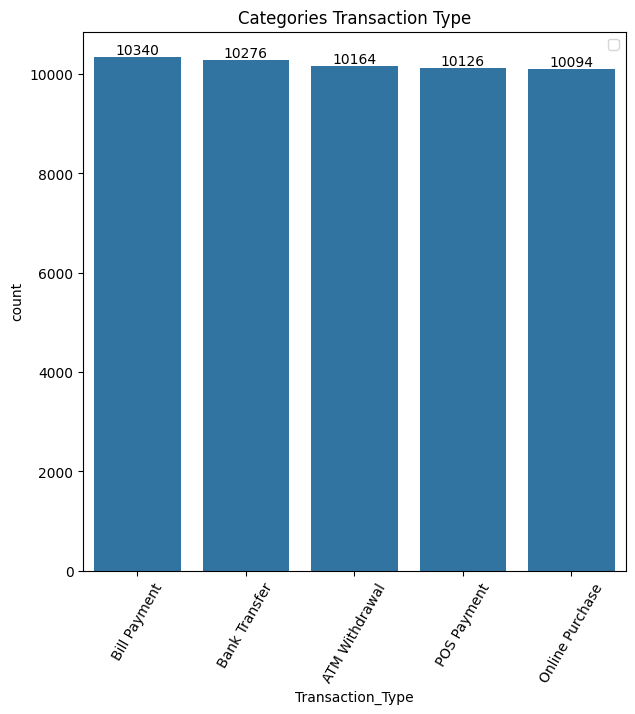

In [55]:
count_transaction_type = df['Transaction_Type'].value_counts()
print(count_transaction_type)

sort = df['Transaction_Type'].value_counts().index
plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Transaction_Type'], order=sort)
ax.bar_label(ax.containers[0])
plt.title('Categories Transaction Type')
plt.xticks(rotation=60)
plt.legend()
plt.show()

Device_Used
Desktop           15795
Mobile            15614
Tablet            15588
Unknown Device     1530
Name: count, dtype: int64


C:\Users\ROG\AppData\Local\Temp\ipykernel_22412\52965231.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


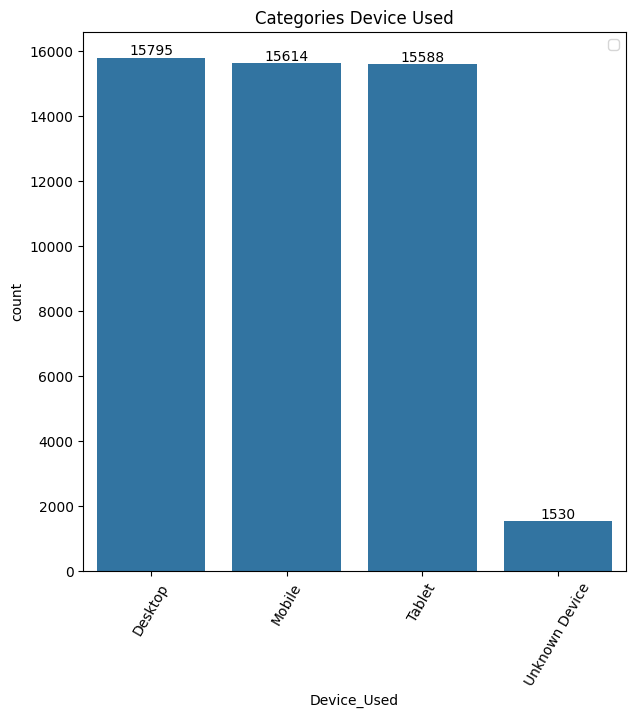

In [56]:
count_device_used = df['Device_Used'].value_counts()
print(count_device_used)

sort = df['Device_Used'].value_counts().index
plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Device_Used'], order=sort)
ax.bar_label(ax.containers[0])
plt.title('Categories Device Used')
plt.xticks(rotation=60)
plt.legend()
plt.show()

Location
Boston           6149
New York         6110
Seattle          6104
Chicago          6071
Houston          6031
Los Angeles      6012
Miami            5991
San Francisco    5985
Name: count, dtype: int64


C:\Users\ROG\AppData\Local\Temp\ipykernel_22412\3912731148.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


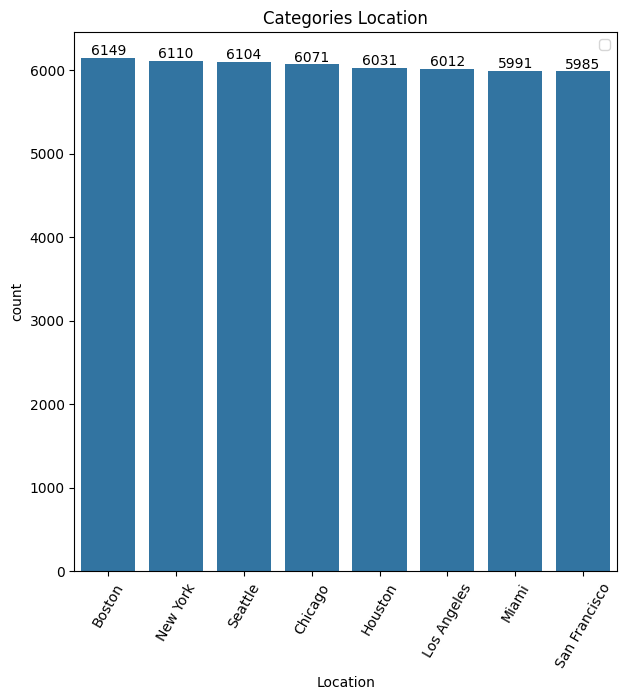

In [57]:
count_location = df['Location'].value_counts()
print(count_location)

sort = df['Location'].value_counts().index
plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Location'], order=sort)
ax.bar_label(ax.containers[0])
plt.title('Categories Location')
plt.xticks(rotation=60)
plt.legend()
plt.show()

Payment_Method
UPI               11887
Debit Card        11802
Net Banking       11666
Credit Card       11646
Invalid Method     1530
Name: count, dtype: int64


C:\Users\ROG\AppData\Local\Temp\ipykernel_22412\2984033767.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


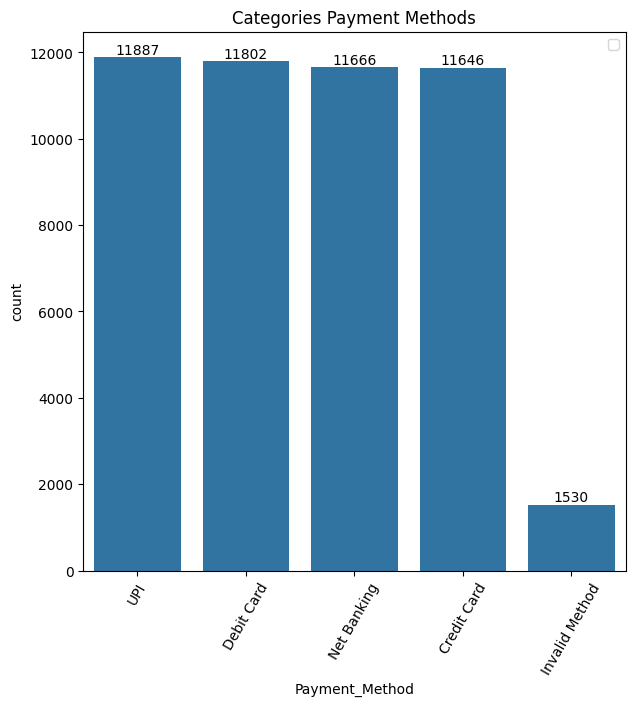

In [58]:
count_payment = df['Payment_Method'].value_counts()
print(count_payment)

sort = df['Payment_Method'].value_counts().index
plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Payment_Method'], order=sort)
ax.bar_label(ax.containers[0])
plt.title('Categories Payment Methods')
plt.xticks(rotation=60)
plt.legend()
plt.show()

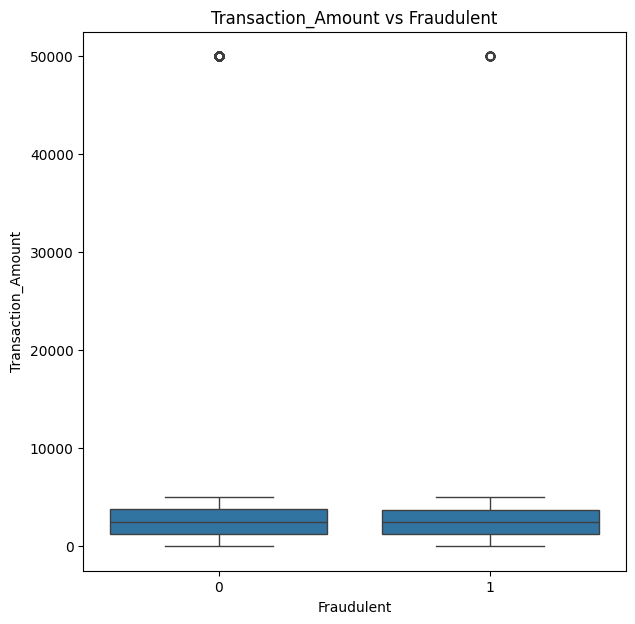

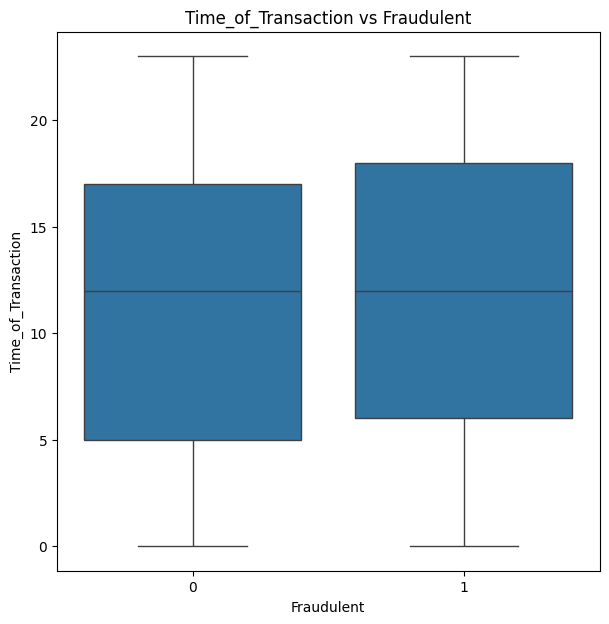

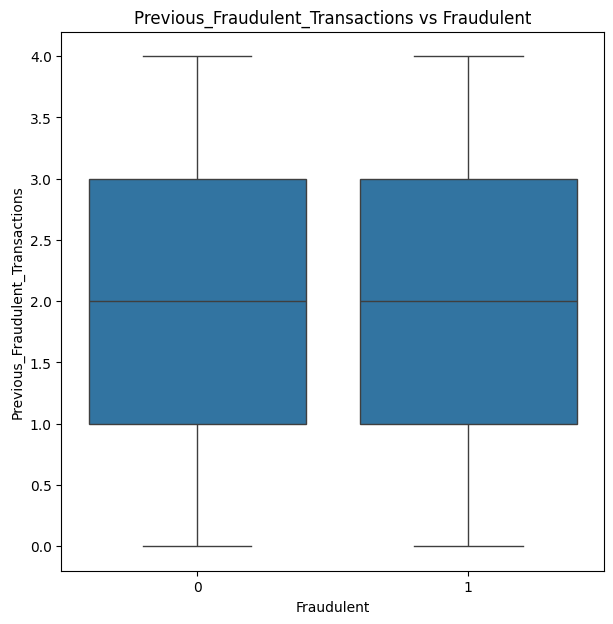

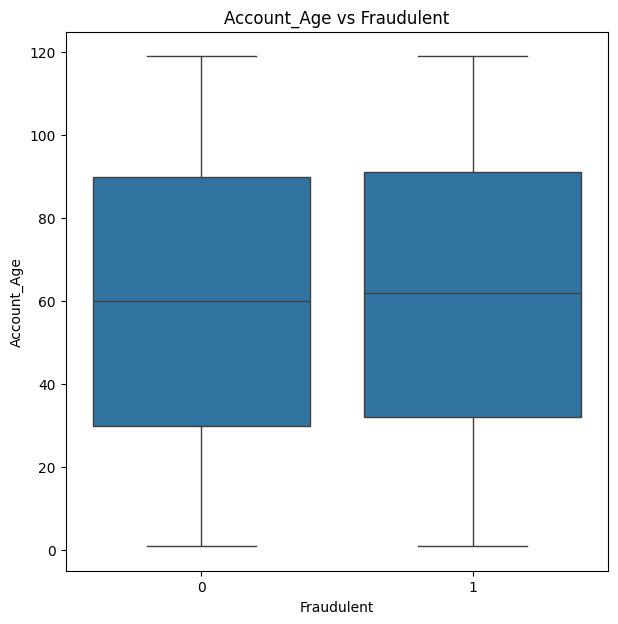

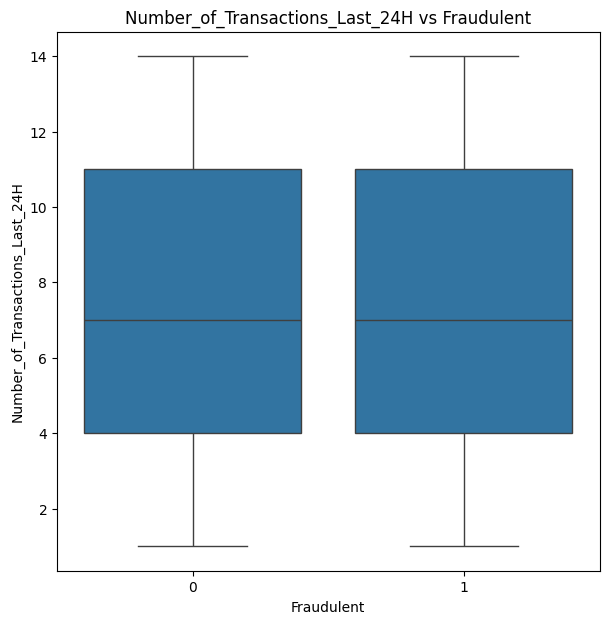

In [59]:
# plt.figure(figsize=(7,7))
# sns.histplot(x=df['Account_Age'], hue=df['Fraudulent'], element='step',kde=True)
# plt.title("Distribution of Account Age")
# plt.show()

numerical_feature = [
    'Transaction_Amount',
    'Time_of_Transaction',
    'Previous_Fraudulent_Transactions',
    'Account_Age',
    'Number_of_Transactions_Last_24H'
]

for feature in numerical_feature :
    plt.figure(figsize=(7,7))
    sns.boxplot(
        data = df,
        x = df['Fraudulent'],
        y= feature,
    )

    plt.title(f'{feature} vs Fraudulent')
    plt.show()


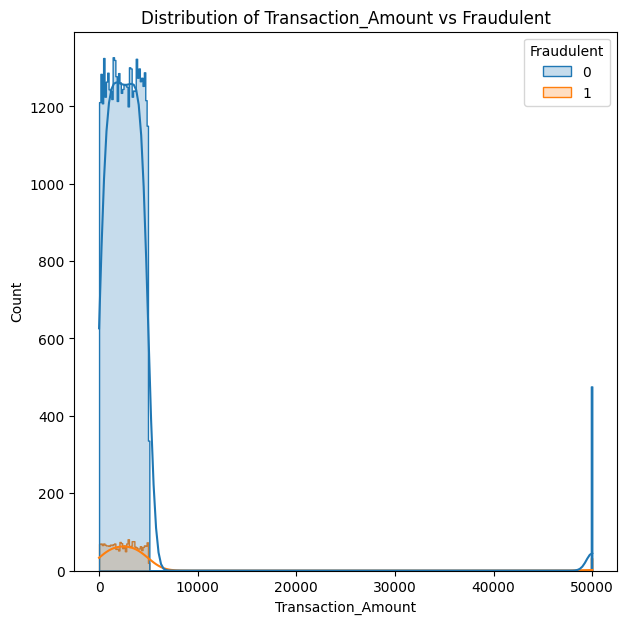

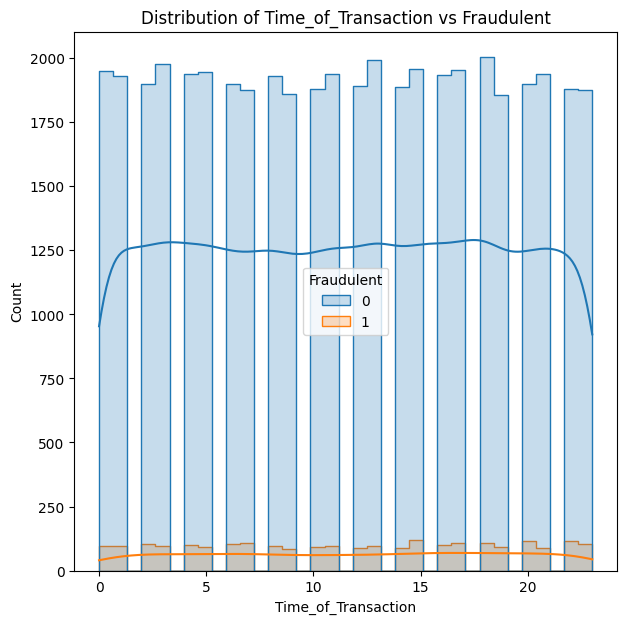

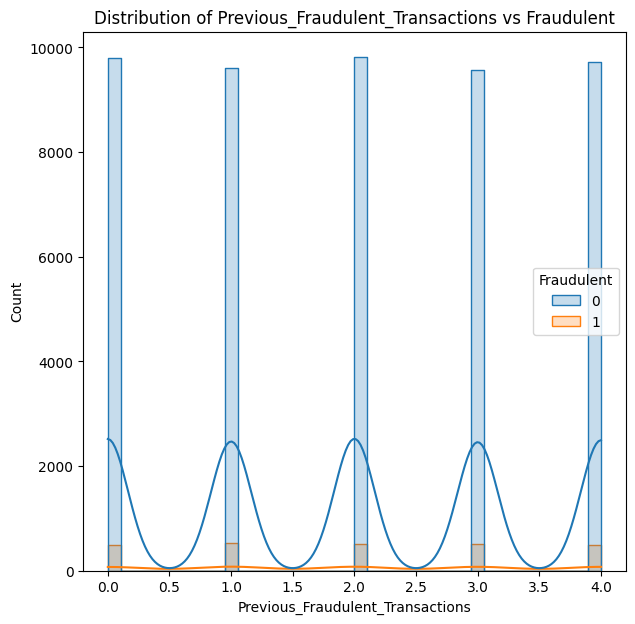

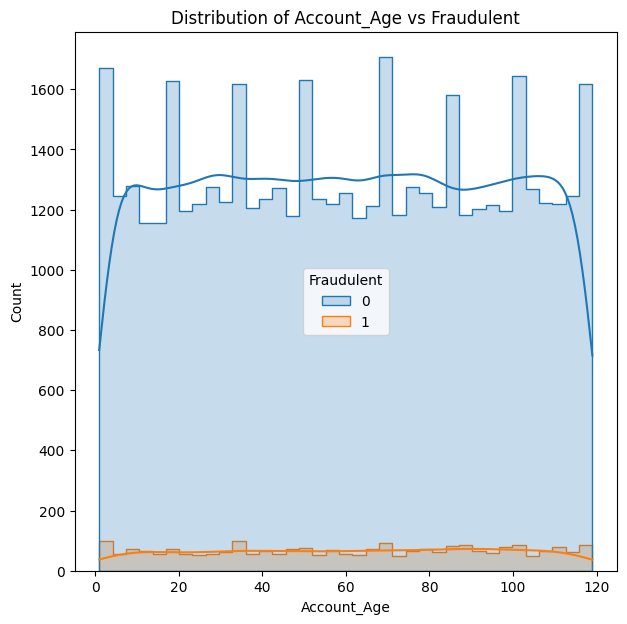

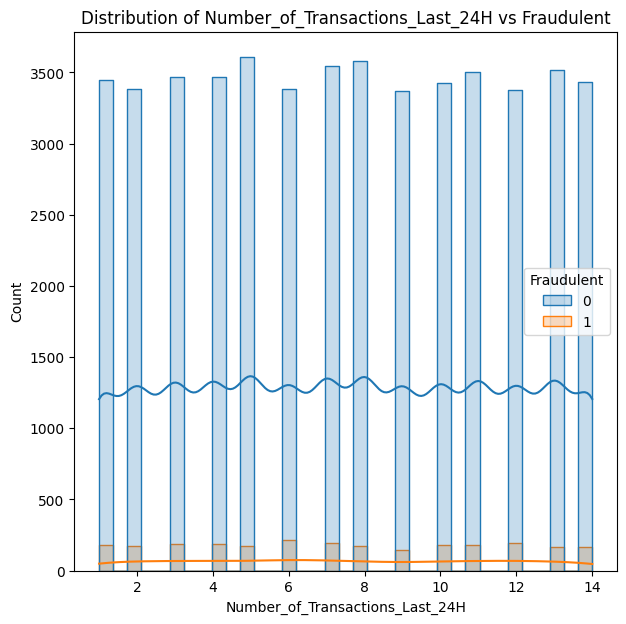

In [60]:
for feature in numerical_feature :
    plt.figure(figsize=(7,7))
    sns.histplot(
        data = df,
        x = feature,
        hue=df['Fraudulent'],
        kde=True,
        element='step'
    )
    plt.title(f'Distribution of {feature} vs Fraudulent')
    plt.show()

Transaction_Type
Online Purchase    524
Bill Payment       512
POS Payment        507
Bank Transfer      494
ATM Withdrawal     473
dtype: int64


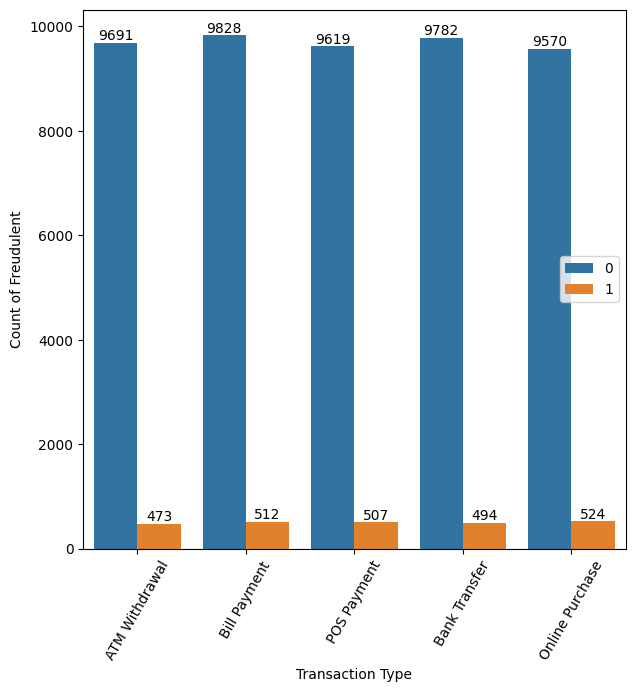

In [61]:
fraud_by_transaction_type = (
    df[df['Fraudulent'] == 1]
    .groupby('Transaction_Type')
    .size()
    .sort_values(ascending=False)
    )
print(fraud_by_transaction_type)


plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Transaction_Type'], hue=df['Fraudulent'])
for containers in ax.containers :
    ax.bar_label(containers)
plt.xticks(rotation=60)
plt.xlabel("Transaction Type")
plt.ylabel("Count of Freudulent")
plt.legend()
plt.show()


Location
Chicago          334
Boston           310
Los Angeles      310
Miami            298
San Francisco    297
New York         290
Houston          282
Seattle          266
dtype: int64


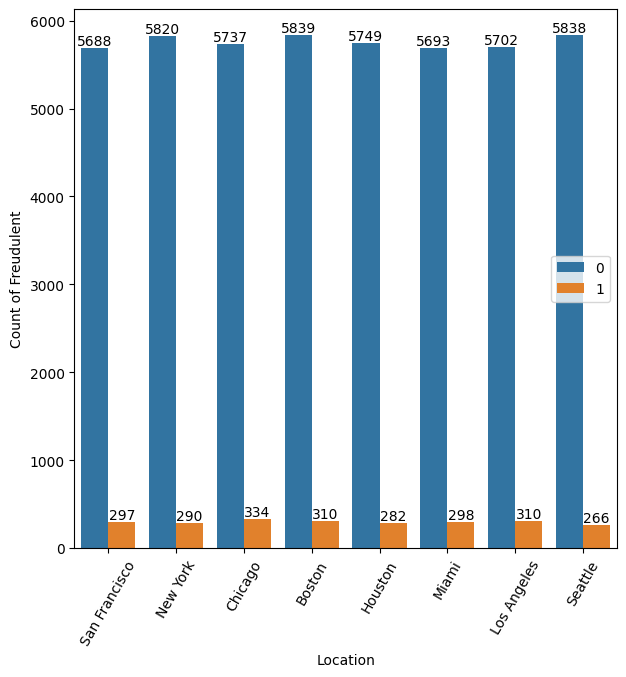

In [62]:
fraud_by_location = df[df['Fraudulent'] == 1].groupby('Location').size().sort_values(ascending=False)
print(fraud_by_location)

plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Location'], hue=df['Fraudulent'])
for containers in ax.containers :
    ax.bar_label(containers)
plt.xticks(rotation=60)
plt.xlabel("Location")
plt.ylabel("Count of Freudulent")
plt.legend()
plt.show()

Payment_Method
UPI               612
Credit Card       574
Net Banking       574
Debit Card        572
Invalid Method     73
dtype: int64


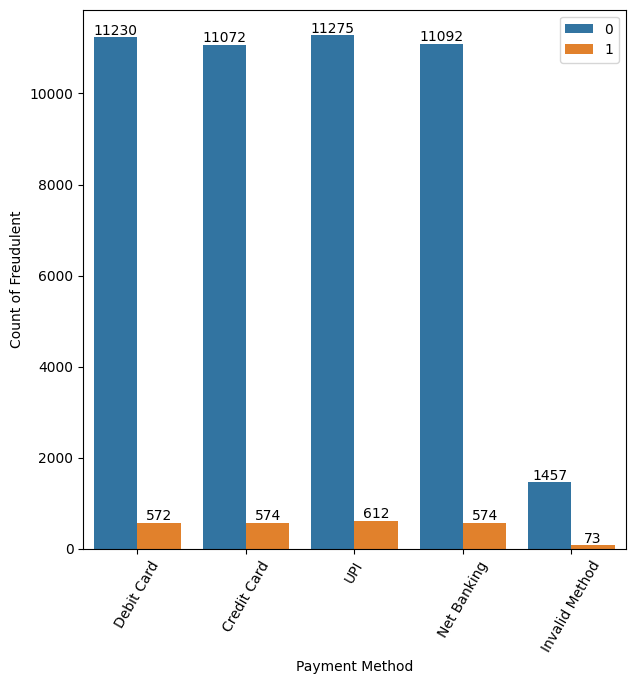

In [63]:
fraud_by_payment_method = (
    df[df['Fraudulent'] == 1]
    .groupby('Payment_Method')
    .size()
    .sort_values(ascending=False)
)
print(fraud_by_payment_method)


plt.figure(figsize=(7,7))
ax = sns.countplot(x=df['Payment_Method'], hue=df['Fraudulent'])
for containers in ax.containers :
    ax.bar_label(containers)
plt.xticks(rotation=60)
plt.xlabel("Payment Method")
plt.ylabel("Count of Freudulent")
plt.legend()
plt.show()

In [64]:
payments_methods = df['Payment_Method'].unique()

result_payment_methods = []

for method in payments_methods :
    total_payment = (df['Payment_Method'] == method).sum()
    fraud_payment = (
        (df['Payment_Method'] == method ) &
        (df['Fraudulent'] == 1)
    ).sum()
    fraud_rate_payment = (fraud_payment / total_payment * 100).round(2)

    # print(f'{method} :')
    # print(f'Total Payment : {total_payment:,}')
    # print(f'Fraud : {fraud_payment:,}')
    # print(f'Fraud Rate : {fraud_rate_payment:,}')
    # print()

    result_payment_methods.append({
        'Method' : method,
        'Total Payment' : total_payment,
        'Fraud' : fraud_payment,
        'Fraud Rate' : fraud_rate_payment
    })

result_payment_method_fraud = pd.DataFrame(result_payment_methods)
print(result_payment_method_fraud.sort_values('Fraud Rate', ascending=False))



           Method  Total Payment  Fraud  Fraud Rate
3             UPI          11887    612        5.15
1     Credit Card          11646    574        4.93
4     Net Banking          11666    574        4.92
0      Debit Card          11802    572        4.85
5  Invalid Method           1530     73        4.77
2             NaN              0      0         NaN


C:\Users\ROG\AppData\Local\Temp\ipykernel_22412\60976751.py:11: RuntimeWarning: invalid value encountered in scalar divide
  fraud_rate_payment = (fraud_payment / total_payment * 100).round(2)


In [65]:
transaction_analysis = df['Transaction_Type'].unique()

result_transaction_type = []

for method in transaction_analysis :
    total_transaction = (df['Transaction_Type'] == method).sum()
    fraud_transaction = (
        (df['Transaction_Type'] == method) &
        (df['Fraudulent'] == 1)
    ).sum()
    fraud_rate_transaction = (fraud_transaction / total_transaction * 100).round(2)
    # print(f'{method} : ')
    # print(f"Total Transaction : {total_transaction:,}")
    # print(f"Fraud : {fraud_transaction:,}")
    # print(f"Fraud Rate : {fraud_rate_transaction:.2f}")
    # print()

    result_transaction_type.append({
            'Method' : method,
            'Total Transaction' : total_transaction,
            'Fraud' : fraud_transaction,
            'Fraud Rate' : fraud_rate_transaction
        })
    
result_transaction_type_fraud = pd.DataFrame(result_transaction_type)
print((result_transaction_type_fraud.sort_values('Fraud Rate',ascending=False)))
   
    
    

            Method  Total Transaction  Fraud  Fraud Rate
4  Online Purchase              10094    524        5.19
2      POS Payment              10126    507        5.01
1     Bill Payment              10340    512        4.95
3    Bank Transfer              10276    494        4.81
0   ATM Withdrawal              10164    473        4.65


In [66]:
device_analysis = df['Device_Used'].unique()

result_device = []

for method in device_analysis:
    total_Device = (df['Device_Used'] == method).sum()
    fraud_Device = (
        (df['Device_Used'] == method) &
        (df['Fraudulent'] == 1)
    ).sum()
    fraud_rate_device = (fraud_Device / total_Device * 100).round(2)

    # print(f'{method} : ')
    # print(f"Total Transaction : {total_Device:,}")
    # print(f"Fraud : {fraud_Device:,}")
    # print(f"Fraud Rate : {fraud_rate_device:.2f}")
    # print()

    result_device.append({
            'Method' : method,
            'Total Transaction' : total_Device,
            'Fraud' : fraud_Device,
            'Fraud Rate' : fraud_rate_device
        })
    
result_device_fraud = pd.DataFrame(result_device)
print((result_device_fraud.sort_values('Fraud Rate',ascending=False)))

    

           Method  Total Transaction  Fraud  Fraud Rate
1          Mobile              15614    806        5.16
4  Unknown Device               1530     75        4.90
2         Desktop              15795    748        4.74
0          Tablet              15588    729        4.68
3             NaN                  0      0         NaN


C:\Users\ROG\AppData\Local\Temp\ipykernel_22412\225195752.py:11: RuntimeWarning: invalid value encountered in scalar divide
  fraud_rate_device = (fraud_Device / total_Device * 100).round(2)


In [67]:
fraud_analysis = (
    df.groupby([
        'Location',
        'Transaction_Type',
        'Payment_Method'
    ]).agg(
        total_transaction_analysis = ('Fraudulent', 'count'),
        fraud_total = ('Fraudulent', 'sum')
    )
    .reset_index()
)

fraud_analysis['Fraude_rate'] = (
    fraud_analysis['fraud_total'] / 
    fraud_analysis['total_transaction_analysis'] * 100
).round(2)

fraud_analysis = fraud_analysis.sort_values(
    'Fraude_rate',
    ascending=False
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
print(fraud_analysis.to_string())

          Location Transaction_Type  Payment_Method  total_transaction_analysis  fraud_total  Fraude_rate
12          Boston     Bill Payment  Invalid Method                          30            3        10.00
142       New York  Online Purchase  Invalid Method                          41            4         9.76
112          Miami     Bill Payment  Invalid Method                          45            4         8.89
37         Chicago     Bill Payment  Invalid Method                          45            4         8.89
109          Miami    Bank Transfer             UPI                         290           25         8.62
41         Chicago  Online Purchase      Debit Card                         261           22         8.43
87     Los Angeles     Bill Payment  Invalid Method                          38            3         7.89
132       New York    Bank Transfer  Invalid Method                          38            3         7.89
88     Los Angeles     Bill Payment     Net Ba

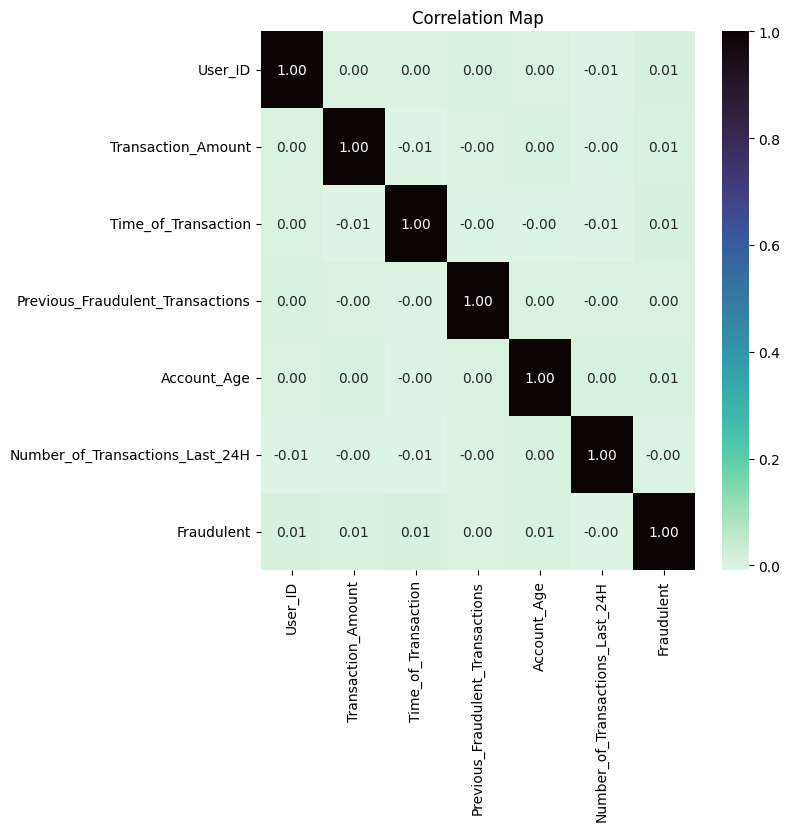

In [68]:
corr_df = df.select_dtypes(include='number').copy()

corr = corr_df.corr()

plt.figure(figsize=(7,7))
sns.heatmap(
    corr,
    cmap='mako_r',
    annot=True,
    fmt='.2f'
)
plt.title("Correlation Map")
# plt.xticks(rotation=60)
plt.show()

# Feature Engineering

### Time Cylic -> kita membuat jam seperti lingkaran supaya data mengetahui jika 23.30 itu berdekatan dengan 00.00

In [69]:
df['time_sin'] = np.sin(2 * np.pi * df['Time_of_Transaction']/ 24) 
df['time_cos'] = np.cos(2 * np.pi * df['Time_of_Transaction'] / 24)

df[
    ['Time_of_Transaction',
    'time_sin',
    'time_cos']
].head(5)

,Time_of_Transaction,time_sin,time_cos
0,16.0,-0.866025,-0.500000
1,13.0,-0.258819,-0.965926
2,NaN,NaN,NaN
3,15.0,-0.707107,-0.707107
4,19.0,-0.965926,0.258819


### Log Transaction amount, ini jg bisa mengurangi skewed karena ini mirip scaling

In [70]:
df['log_transaction_amount'] = np.log1p(df['Transaction_Amount'])

### Feature Binary Fraudulent

In [71]:
df['has_previous_fraud'] = (
    df['Previous_Fraudulent_Transactions'] > 0
).astype(int)

# Splitting Data

In [72]:
# Splitting Data first because i won't make a leak data
from sklearn.model_selection import train_test_split

X = df.drop(columns=[
    'Fraudulent',
    'Transaction_ID',
    'User_ID'
])
y = df['Fraudulent']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    stratify=y
)

print("Splitting Data Success")

Splitting Data Success


# Data Handling - Do Splitiing Data first because we wont to data leakage in model so we do splitting data first and we get X_train and the do Simpleimputer

In [73]:
df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
).head(20)

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent,time_sin,time_cos,log_transaction_amount,has_previous_fraud
1003,T1004,4190,2828.74,Bill Payment,21.0,Tablet,Boston,2,97,14,Credit Card,0,-7.071068e-01,0.707107,7.947940,1
50688,T1004,4190,2828.74,Bill Payment,21.0,Tablet,Boston,2,97,14,Credit Card,0,-7.071068e-01,0.707107,7.947940,1
10074,T10075,3686,3700.47,ATM Withdrawal,7.0,Mobile,San Francisco,1,38,10,Net Banking,0,9.659258e-01,-0.258819,8.216485,1
50440,T10075,3686,3700.47,ATM Withdrawal,7.0,Mobile,San Francisco,1,38,10,Net Banking,0,9.659258e-01,-0.258819,8.216485,1
10075,T10076,2798,1775.37,Online Purchase,NaN,Desktop,Seattle,4,33,4,Credit Card,1,NaN,NaN,7.482327,1
50952,T10076,2798,1775.37,Online Purchase,NaN,Desktop,Seattle,4,33,4,Credit Card,1,NaN,NaN,7.482327,1
10192,T10193,1225,NaN,ATM Withdrawal,5.0,Tablet,Los Angeles,1,74,13,UPI,0,9.659258e-01,0.258819,NaN,1
50494,T10193,1225,NaN,ATM Withdrawal,5.0,Tablet,Los Angeles,1,74,13,UPI,0,9.659258e-01,0.258819,NaN,1
1030,T1031,1475,2498.40,Bill Payment,8.0,Mobile,New York,2,56,13,Credit Card,0,8.660254e-01,-0.500000,7.823806,1
50447,T1031,1475,2498.40,Bill Payment,8.0,Mobile,New York,2,56,13,Credit Card,0,8.660254e-01,-0.500000,7.823806,1


In [74]:
feature_cols = [
    col for col in df.columns
    if col not in ['Transaction_ID']
]

df.duplicated(subset=feature_cols).sum()

np.int64(881)

In [75]:
df = df.drop_duplicates().reset_index(drop=True)

In [ ]:
# Data Handling
from sklearn.impute import SimpleImputer

numerical_feature = [
    'Transaction_Amount',
    'Time_of_Transaction',
    'Previous_Fraudulent_Transactions',
    'Account_Age',
    'Number_of_Transactions_Last_24H',

    # Feature Engineering
    'time_sin',
    'time_cos',
    'log_transaction_amount',
    'has_previous_fraud'
]

categorical_feature =[
    'Transaction_Type',
    'Device_Used',
    'Location',
    'Payment_Method'
]

numeric_imputer = SimpleImputer(strategy='median')
categorical_imputer = SimpleImputer(strategy='most_frequent')

X_train_numeric_imputer = numeric_imputer.fit_transform(
    X_train[numerical_feature]
)

X_test_numeric_imputer = numeric_imputer.transform(
    X_test[numerical_feature]
)

X_train_categorical_imputer = categorical_imputer.fit_transform(
    X_train[categorical_feature]
)

X_test_categorical_imputer = categorical_imputer.transform(
    X_test[categorical_feature]
)

print("Handling Missing Value Successfully!")

Handling Missing Value Successfully!


# Data Preparation

In [77]:
# Mutual Infromation for Numerical 
from sklearn.feature_selection import mutual_info_classif

mi_numerical = mutual_info_classif(
    X_train_numeric_imputer,
    y_train,
    discrete_features=False,
    random_state=42
)
result_mi_numerical =pd.DataFrame({
    'Feature' : numerical_feature,
    'Numerical Mutual Information' : mi_numerical
})

print(result_mi_numerical.sort_values('Numerical Mutual Information', ascending=False))



                            Feature  Numerical Mutual Information
8                has_previous_fraud                      0.005823
4   Number_of_Transactions_Last_24H                      0.003892
2  Previous_Fraudulent_Transactions                      0.002173
0                Transaction_Amount                      0.001834
6                          time_cos                      0.001592
1               Time_of_Transaction                      0.001401
3                       Account_Age                      0.000788
7            log_transaction_amount                      0.000711
5                          time_sin                      0.000000


In [78]:
# Do Chi Contingency
from scipy.stats import chi2_contingency

# Create X_train_categorical_imputer because result from X_train_C is Numpy Array not Data Frame
X_feature_chi = pd.DataFrame(
    X_train_categorical_imputer,
    columns=categorical_feature,
    index= X_train.index
)
result = []

for feature in categorical_feature :
    table = pd.crosstab(X_feature_chi[feature], y_train)

    chi_stat, p_value, dof, expected = chi2_contingency(table)
    result.append({
        'Feature' : feature,
        'Chi_Squred' : chi_stat,
        'P Value' : p_value,
        'dof' : dof
    })

df_chi_result = pd.DataFrame(result)
alpha = 0.05
alpha = 0.05

df_chi_result['Significant'] = (
    df_chi_result['P Value'] < alpha
)

display(
    df_chi_result.sort_values(
        'P Value',
        ascending=True
    )
)

,Feature,Chi_Squred,P Value,dof,Significant
0,Transaction_Type,6.936725,0.139270,4,False
1,Device_Used,3.830049,0.280410,3,False
2,Location,7.852608,0.345770,7,False
3,Payment_Method,0.183134,0.996055,4,False


In [79]:
# Do Mutual Information for Categorical Feature
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif

encoder = OrdinalEncoder()

X_train_encode = encoder.fit_transform(X_train_categorical_imputer)

categorical_mi = mutual_info_classif(
    X_train_encode,
    y_train,
    discrete_features=True,
    random_state=42
)

categorical_mi_result = pd.DataFrame ({
    'Feature Chi' : categorical_feature,
    'Categorical Mutual Information' : categorical_mi
})

print(categorical_mi_result.sort_values('Categorical Mutual Information', ascending=False))

        Feature Chi  Categorical Mutual Information
2          Location                        0.000101
0  Transaction_Type                        0.000091
1       Device_Used                        0.000050
3    Payment_Method                        0.000002


# Baseline

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numerical_feature_model_basline = [
    'Transaction_Amount',
    'Time_of_Transaction',
    'Previous_Fraudulent_Transactions',
    'Account_Age',
    'Number_of_Transactions_Last_24H', 

    # Feature Engineering
    'time_sin',
    'time_cos',
    'log_transaction_amount',
    'has_previous_fraud'
]

categorical_feature_model_baseline =[
    'Transaction_Type',
    'Device_Used',
    'Location',
    'Payment_Method'
]

numerical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([ 
    ('numerical', numerical_transformer, numerical_feature_model_basline),
    ('cat', categorical_transformer, categorical_feature_model_baseline)
])

random_forest = RandomForestClassifier(
    n_estimators=200,
    criterion='gini',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    max_depth=None,
    min_samples_leaf=1,
    min_samples_split=2
)

model_baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', random_forest)
])

print("Preprocessing Data Succesfully")


Preprocessing Data Succesfully


# Train Baseline Model

In [92]:
model_baseline.fit(X_train, y_train)

y_pred = model_baseline.predict(X_test)

y_pred_proba = model_baseline.predict_proba(X_test)[:,1]

# Evaluation Baseline

In [93]:
from sklearn.metrics import (
    classification_report, 
    accuracy_score,
    precision_score, 
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
classification_reports = classification_report(y_test, y_pred, target_names=['Non-Fraud','Fraud'])
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)


print("Clasification Report : ",classification_reports)
print("Accuracy Score : ",accuracy)
print("Recall Score : ",recall)
print("f1 Score : ",f1)
print("ROC AUC SCORE : ",roc_auc)
print("average_precision Score : ",average_precision)



Clasification Report :                precision    recall  f1-score   support

   Non-Fraud       0.95      1.00      0.98     12123
       Fraud       0.95      0.03      0.06       627

    accuracy                           0.95     12750
   macro avg       0.95      0.51      0.52     12750
weighted avg       0.95      0.95      0.93     12750

Accuracy Score :  0.952156862745098
Recall Score :  0.028708133971291867
f1 Score :  0.05572755417956656
ROC AUC SCORE :  0.5092314015261696
average_precision Score :  0.08675422370531895


# Smotenc

In [105]:
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as Imbpipeline
from imblearn.over_sampling import SMOTENC

numerical_feature_model_smotenc = [
    'Transaction_Amount',
    'Time_of_Transaction',
    'Previous_Fraudulent_Transactions',
    'Account_Age',
    'Number_of_Transactions_Last_24H', 

    # Feature Engineering
    'time_sin',
    'time_cos',
    'log_transaction_amount',
    'has_previous_fraud'
]

categorical_feature_model_smotenc =[
    'Transaction_Type',
    'Device_Used',
    'Location',
    'Payment_Method'
]

numerical_transformer_smotenc = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer_smotenc = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor_before_smotenc = ColumnTransformer([
    (
        'numerical',
        numerical_transformer_smotenc,
        numerical_feature_model_smotenc
    ),
    (
        'categorical',
        categorical_transformer_smotenc,
        categorical_feature_model_smotenc
    )
])

cat_indicate = list(
    range(
        len(numerical_feature_model_smotenc),
        len(numerical_feature_model_smotenc) + len(categorical_feature_model_smotenc)
    )
)

preprocessor_after_smotenc = ColumnTransformer([
    ('numerical', 'passthrough', list(range(len(numerical_feature_model_smotenc)))),
    ('categorical', OneHotEncoder(handle_unknown='ignore'),cat_indicate)
])

model_with_smotenc = Imbpipeline([
    ('preprocessor_before_smotenc', preprocessor_before_smotenc),
    ('smotenc', SMOTENC(categorical_features= cat_indicate, random_state=42)),
    ('preprocessor_after_smotenc', preprocessor_after_smotenc),
    # ('rf', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
]) 

In [100]:
model_with_smotenc.fit(X_train, y_train)

,steps,"[('preprocessor_before_smotenc', ...), ('smotenc', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](13,)","['Transaction_Amount','Transaction_Type','Time_of_Transaction',..., 'time_cos','log_transaction_amount','has_previous_fraud']"
n_features_in_,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


# Evaluation SMOTENC

In [101]:
y_pred_smotenc = model_with_smotenc.predict(X_test)
y_proba_smotenc = model_with_smotenc.predict_proba(X_test)[:, 1]


print(
    classification_report(
        y_test,
        y_pred_smotenc,
        target_names=['Non-Fraud', 'Fraud'],
        zero_division=0
    )
)


              precision    recall  f1-score   support

   Non-Fraud       0.95      1.00      0.98     12123
       Fraud       1.00      0.03      0.06       627

    accuracy                           0.95     12750
   macro avg       0.98      0.51      0.52     12750
weighted avg       0.95      0.95      0.93     12750



In [102]:
accuracy = accuracy_score(
    y_test,
    y_pred_smotenc
)

precision = precision_score(
    y_test,
    y_pred_smotenc,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred_smotenc,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred_smotenc,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_proba_smotenc
)

pr_auc = average_precision_score(
    y_test,
    y_proba_smotenc
)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

Accuracy  : 0.9522
Precision : 1.0000
Recall    : 0.0287
F1 Score  : 0.0558
ROC-AUC   : 0.5207
PR-AUC    : 0.0849


In [103]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(
    y_test,
    y_pred_smotenc
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[12123     0]
 [  609    18]]


# Crossvalidation Baseline

In [83]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_result = cross_validate(
    model_baseline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        'precision': "precision",
        'recall' : 'recall',
        'f1' : 'f1',
        'roc_auc' : 'roc_auc',
        'average_precision' : 'average_precision'
    },
    n_jobs=-1,
    error_score='raise'
)

print("Mean Precision:", cv_result['test_precision'].mean())
print("Mean Recall   :", cv_result['test_recall'].mean())
print("Mean F1       :", cv_result['test_f1'].mean())
print("Mean ROC-AUC  :", cv_result['test_roc_auc'].mean())
print("Mean PR-AUC   :", cv_result['test_average_precision'].mean())

Mean Precision: 0.7771717171717172
Mean Recall   : 0.023893842767650546
Mean F1       : 0.046321705718204834
Mean ROC-AUC  : 0.5179770861205426
Mean PR-AUC   : 0.08047982066367292


# Crossvalidation with randomsearchCV

In [84]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'classifier__n_estimators': [200, 300, 500],
    'classifier__criterion': ['gini', 'entropy', 'log_loss'],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

random_search = RandomizedSearchCV(
    estimator=model_baseline,
    param_distributions= param_dist,
    n_iter=20,
    scoring='f1',
    verbose=2,
    cv=cv,
    random_state=42,
    n_jobs=-1,

)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("Best CV F1:", random_search.best_score_)

best_model = random_search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'classifier__n_estimators': 500, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__criterion': 'gini', 'classifier__class_weight': 'balanced'}
Best CV F1: 0.0788902227655214


# Evaluation RandomSearch CV

In [85]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Fraud', 'Fraud']
))

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_proba))
print("PR-AUC   :", average_precision_score(y_test, y_proba))

              precision    recall  f1-score   support

   Non-Fraud       0.95      0.91      0.93     12123
       Fraud       0.06      0.12      0.08       627

    accuracy                           0.87     12750
   macro avg       0.51      0.51      0.51     12750
weighted avg       0.91      0.87      0.89     12750

Accuracy : 0.8710588235294118
Recall   : 0.11642743221690591
F1       : 0.08156424581005586
ROC-AUC  : 0.4993645016307463
PR-AUC   : 0.06409641402422414


# Crossvalidation SMOTENC

In [106]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)


param_dist = {
    'classifier__n_estimators': [200, 300, 500],
    'classifier__criterion': ['gini', 'entropy', 'log_loss'],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

random_search = RandomizedSearchCV(
    estimator=model_with_smotenc,
    param_distributions= param_dist,
    n_iter=20,
    scoring='f1',
    verbose=2,
    cv=cv,
    random_state=42,
    n_jobs=-1,

)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("Best CV F1:", random_search.best_score_)

best_model = random_search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 10, 'classifier__criterion': 'gini', 'classifier__class_weight': 'balanced_subsample'}
Best CV F1: 0.06991238148707071


# Evaluation SMOTENC with RandomSearch CV

In [108]:
y_pred = best_model.predict(X_test)
y_proba_smotect_cv = best_model.predict_proba(X_test)[:, 1]

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Fraud', 'Fraud']
))

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_proba))
print("PR-AUC   :", average_precision_score(y_test, y_proba))

              precision    recall  f1-score   support

   Non-Fraud       0.95      0.86      0.90     12123
       Fraud       0.05      0.14      0.07       627

    accuracy                           0.82     12750
   macro avg       0.50      0.50      0.49     12750
weighted avg       0.91      0.82      0.86     12750

Accuracy : 0.8243921568627451
Recall   : 0.1419457735247209
F1       : 0.07364501448076127
ROC-AUC  : 0.506434906114506
PR-AUC   : 0.051128689088195636


In [109]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 0.51, 0.05)
y_proba = best_model.predict_proba(X_test)[:, 1]
results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1': f1
    })
threshold_result = pd.DataFrame(results)

display(threshold_result)
threshold_result.loc[
    threshold_result['F1'].idxmax()
]

,Threshold,Precision,Recall,F1
0,0.05,0.049176,1.000000,0.093743
1,0.10,0.049179,0.993620,0.093719
2,0.15,0.048871,0.925040,0.092837
3,0.20,0.049491,0.853270,0.093556
4,0.25,0.048978,0.722488,0.091738
5,0.30,0.049881,0.599681,0.092100
6,0.35,0.051393,0.452951,0.092313
7,0.40,0.048805,0.309410,0.084311
8,0.45,0.051662,0.228070,0.084242
9,0.50,0.049721,0.141946,0.073645


Threshold    0.050000
Precision    0.049176
Recall       1.000000
F1           0.093743
Name: 0, dtype: float64

In [86]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 0.51, 0.05)

results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1': f1
    })
threshold_result = pd.DataFrame(results)

display(threshold_result)
threshold_result.loc[
    threshold_result['F1'].idxmax()
]

,Threshold,Precision,Recall,F1
0,0.05,0.049176,1.000000,0.093743
1,0.10,0.049176,1.000000,0.093743
2,0.15,0.049176,1.000000,0.093743
3,0.20,0.049184,1.000000,0.093757
4,0.25,0.049167,0.998405,0.093720
5,0.30,0.049156,0.993620,0.093677
6,0.35,0.048939,0.960128,0.093131
7,0.40,0.048750,0.811802,0.091977
8,0.45,0.046754,0.443381,0.084588
9,0.50,0.062769,0.116427,0.081564


Threshold    0.200000
Precision    0.049184
Recall       1.000000
F1           0.093757
Name: 3, dtype: float64

In [104]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 0.51, 0.05)
y_proba = model_with_smotenc.predict_proba(X_test)[:,1]
results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1': f1
    })
threshold_result = pd.DataFrame(results)

display(threshold_result)
threshold_result.loc[
    threshold_result['F1'].idxmax()
]

,Threshold,Precision,Recall,F1
0,0.05,0.049638,0.862839,0.093875
1,0.10,0.052559,0.483254,0.094806
2,0.15,0.057399,0.204147,0.089604
3,0.20,0.073789,0.106858,0.087296
4,0.25,0.108359,0.055821,0.073684
5,0.30,0.194444,0.033493,0.057143
6,0.35,0.434783,0.031898,0.059435
7,0.40,0.612903,0.030303,0.057751
8,0.45,0.857143,0.028708,0.055556
9,0.50,1.000000,0.028708,0.055814


Threshold    0.100000
Precision    0.052559
Recall       0.483254
F1           0.094806
Name: 1, dtype: float64